In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
ds=pd.read_csv("flower_u.csv")
ds.head()

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


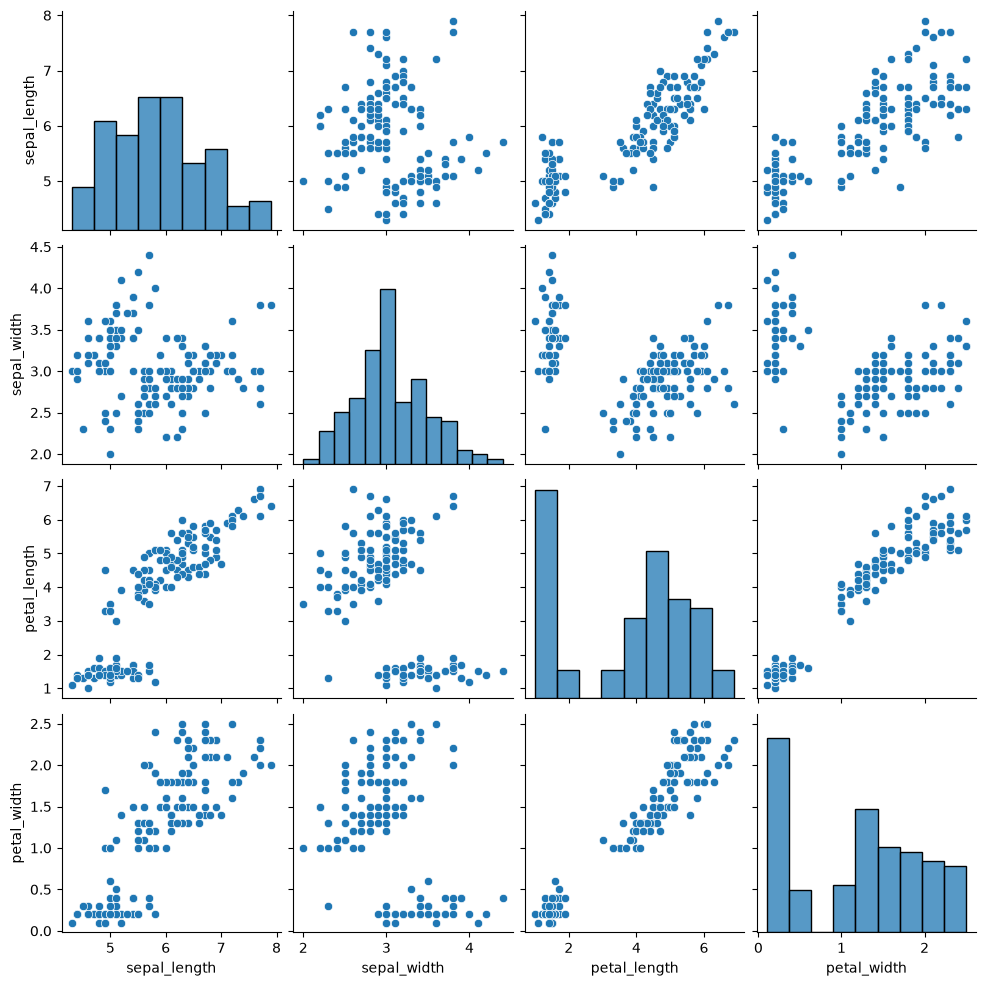

In [ ]:
sns.pairplot(data=ds)

In [ ]:
from sklearn.cluster import KMeans
wcss=[]
for i in range(2,21):
    km=KMeans(n_clusters=i,init="k-means++")
    km.fit(ds)
    ini=km.inertia_ #give wcss value
    wcss.append(ini)
wcss

[152.34795176035792,
 78.85144142614601,
 57.38387326549491,
 49.97767846030011,
 41.82786904761905,
 34.421674242424245,
 30.598185064935066,
 30.871593003230004,
 28.137987429237427,
 24.87212246474603,
 23.637507872846108,
 22.210396309400956,
 20.811366780922896,
 21.06228768453769,
 18.638899251333463,
 17.4758831436881,
 16.801843370681606,
 16.877151015651016,
 15.300027310924374]

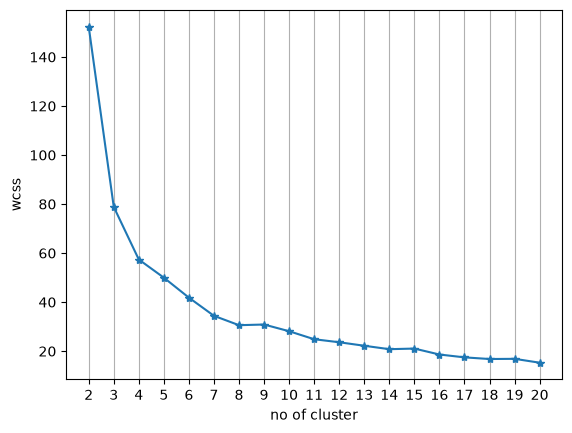

In [7]:
plt.plot([i for i in range(2,21)],wcss,marker="*")
plt.xlabel("no of cluster")
plt.xticks([i for i in range(2,21)])
plt.ylabel("wcss")
plt.grid(axis="x")
plt.show()


In [8]:
# since the elbow point is at 3 we will do 3 cluster
km=KMeans(n_clusters=3)
pred=km.fit_predict(ds)


In [9]:
from sklearn.metrics import silhouette_score
km_l=km.labels_
silhouette_score(ds,labels=km_l)


0.5528190123564102

In [ ]:
ss=[]
for i in range(2,21):
    km1=KMeans(n_clusters=i)
    km1.fit(ds)
    sh=silhouette_score(ds,km1.labels_)
    ss.append(sh)
ss

[0.6810461692117465,
 0.5528190123564102,
 0.49535632852885064,
 0.4609502384437911,
 0.4820957255017657,
 0.30470801672003084,
 0.4295954437981525,
 0.3498070856854406,
 0.2868501747692589,
 0.29111231835436013,
 0.3073005454938118,
 0.3025533341260752,
 0.29686565620711036,
 0.2639773153560869,
 0.2878070639800962,
 0.2458582738806725,
 0.27286116747163114,
 0.2590462495388441,
 0.26366302909527556]

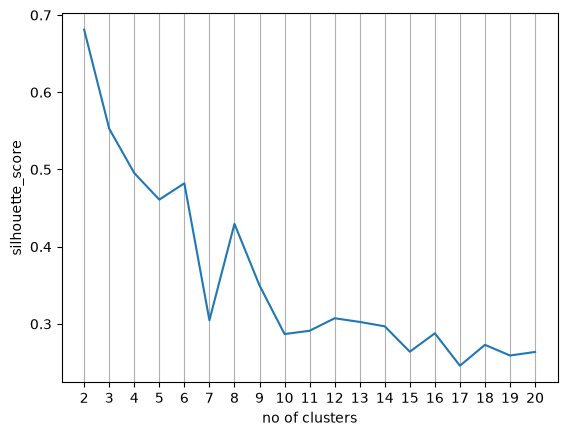

In [ ]:
no_col=[j for j in range(2,21)]
plt.plot(no_col,ss)
plt.xlabel("no of clusters")
plt.ylabel("silhouette_score")
plt.xticks(no_col)
plt.grid(axis="x")
plt.show()

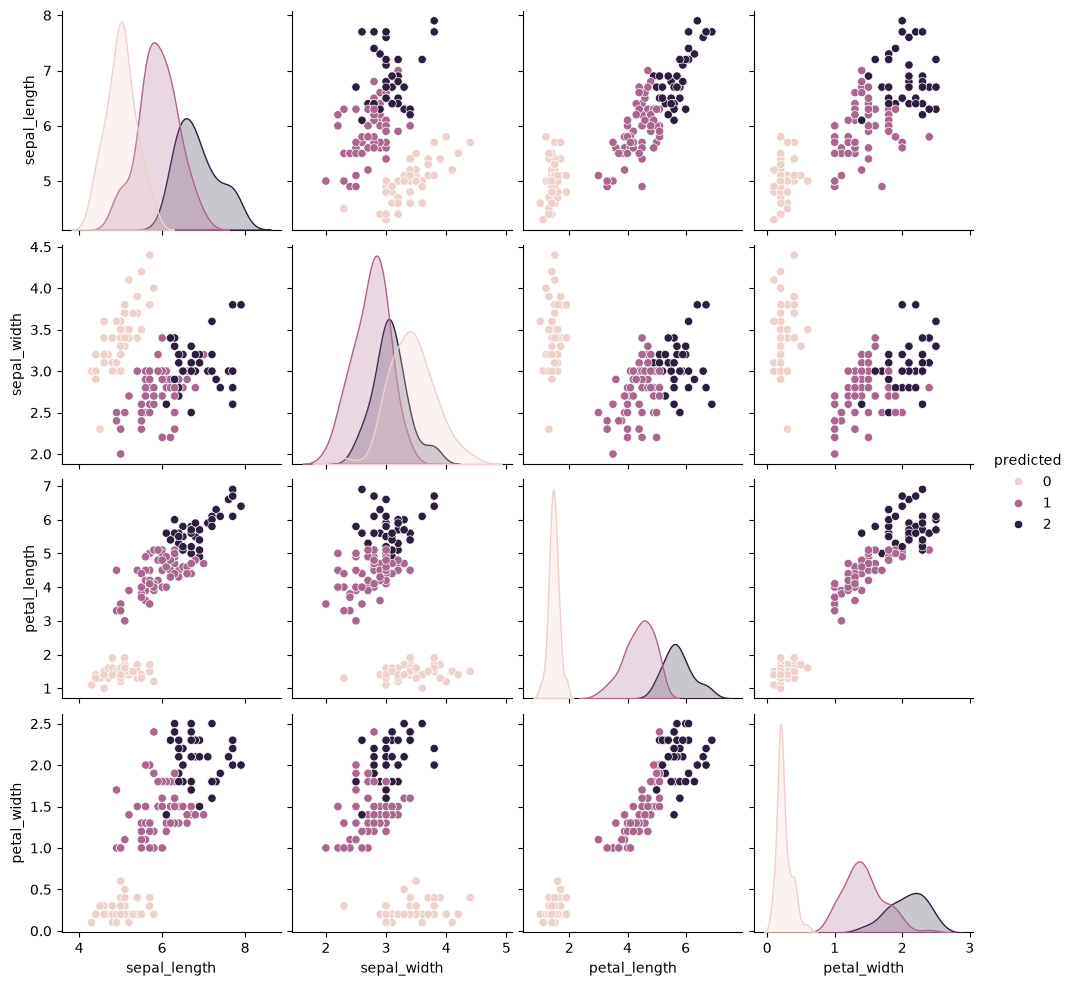

In [ ]:
ds["predicted"]=pred
sns.pairplot(data=ds,hue="predicted")

In [ ]:
org_ds=pd.read_csv("iris_label.csv")
org_ds.head()

FileNotFoundError: [Errno 2] No such file or directory: 'iris_label.csv'

In [ ]:
sns.pairplot(data=org_ds,hue="species")

In [ ]:
x=org_ds.iloc[:,:-1]
y=org_ds["species"]

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,train_size=0.8)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rnf=RandomForestClassifier(n_estimators=30)
rnf.fit(x_train,y_train)
rnf.score(x_train,y_train),rnf.score(x_test,y_test)

In [ ]:
from sklearn.ensemble import BaggingClassifier
bagg=BaggingClassifier(estimator=RandomForestClassifier(n_estimators=30),n_estimators=30)
bagg.fit(x_train,y_train)
bagg.score(x_train,y_train),bagg.score(x_test,y_test)

In [ ]:
print("Random Forest Classifier")
print("Training score:",rnf.score(x_train,y_train))
print("Testing score:",rnf.score(x_test,y_test))

print("Bagged Random Forest")
print("Training score:",bagg.score(x_train,y_train))
print("Testing score:",bagg.score(x_test,y_test))